# SQL Analysis and Visualization
This notebook executes the analytical views defined in `db/views.sql`, visualizes key performance metrics, and extracts insights regarding user behavior, swap patterns, and order conversions.

In [17]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from config import DATABASE_URL
from sqlalchemy import create_engine

# Visualization style preferences
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Quick connection test using the engine
engine = create_engine(DATABASE_URL)
with engine.connect() as conn:
    print("Successfully connected to the local PostgreSQL database via config!")

Successfully connected to the local PostgreSQL database via config!


## 1. Recipe & Meal Role Performance Analysis
Loading the `v_recipe_performance` view to evaluate acceptance, swap, skip, and cook rates across different meal roles.

,recipe_code,recipe_name,meal_role,diet,course,prep_time_min,cook_time_min,cost_tier,difficulty_level,total_interactions,acceptance_rate_pct,swap_rate_pct,skip_rate_pct,cook_rate_pct
0,RCP-SHCXT-FJ8FYRY0FZHR,Lentil Thogayal,condiment,"{pureveg,vegan}",{side},8,10,budget_friendly,EASY,14,100.00,0.00,0.00,0.0
1,RCP-SHCXT-2MWA2C3TXB01,Cucumber Yogurt Pachadi,condiment,{pureveg},{side},15,5,budget_friendly,EASY,11,100.00,0.00,0.00,0.0
2,RCP-SHCXT-M6XXH8KDTA2B,Rajma,lentil,"{pureveg,vegan}",{side},15,40,budget_friendly,MEDIUM,14,92.86,7.14,0.00,0.0
3,RCP-SHCXT-128WJ4TD8PVE,Meen Rava Fry,main,{nonveg},{main},15,20,mid_range,MEDIUM,56,85.71,8.93,5.36,0.0
4,RCP-SHCXT-1SD9R6QN31KW,Basundi,dessert,"{pureveg,sattvic}",{dessert},10,50,mid_range,MEDIUM,7,85.71,14.29,0.00,0.0


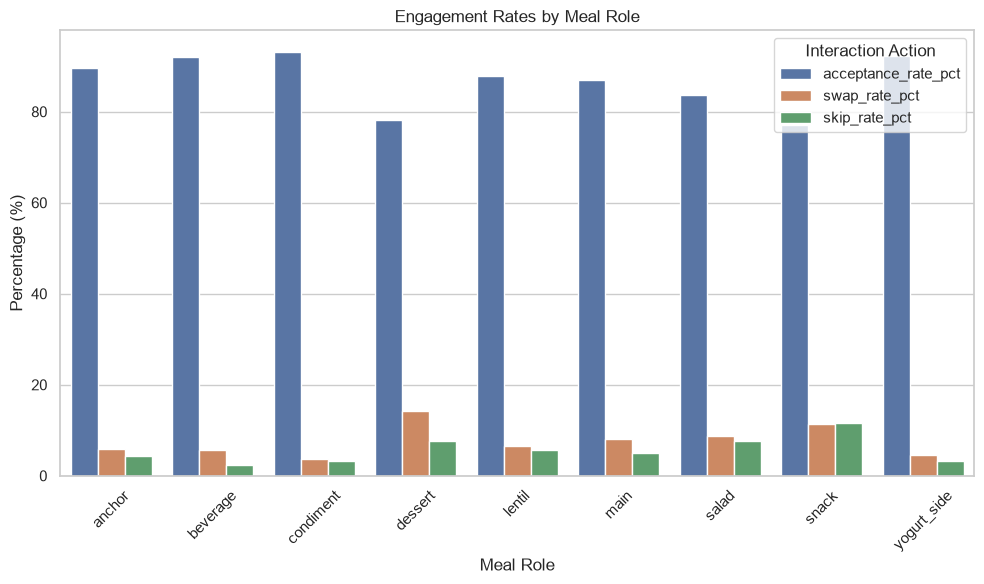

In [18]:
# Query the recipe performance view from the database
query_recipe_perf = "SELECT * FROM v_recipe_performance;"
df_recipe_perf = pd.read_sql(query_recipe_perf, engine)

# Display the first few rows of the recipe performance dataset
display(df_recipe_perf.head())

# Aggregate performance metrics by meal role to analyze user behavior per category
df_meal_role_summary = df_recipe_perf.groupby('meal_role').agg({
    'acceptance_rate_pct': 'mean',
    'swap_rate_pct': 'mean',
    'skip_rate_pct': 'mean',
    'total_interactions': 'sum'
}).reset_index()

# Plot acceptance vs swap rates by meal role to identify friction points
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_meal_role_summary.melt(id_vars='meal_role', value_vars=['acceptance_rate_pct', 'swap_rate_pct', 'skip_rate_pct']),
    x='meal_role',
    y='value',
    hue='variable'
)

# This chart visualizes how user engagement metrics (acceptance, swap, skip percentages) vary across different meal roles in the recommendation engine.
plt.title('Engagement Rates by Meal Role')
plt.xlabel('Meal Role')
plt.ylabel('Percentage (%)')
plt.legend(title='Interaction Action')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Most Common Swap Pairs ($A \rightarrow B$ Transitions)
Analyzing the `v_common_swap_pairs` view to identify which dishes users frequently swap away from and what they substitute them with.

,original_recipe_code,original_recipe_name,original_meal_role,swapped_to_recipe_code,swapped_to_recipe_name,swapped_to_meal_role,transition_count
0,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NKJWJY5WX88X...,Moist & Fudgy Chocolate Cake,None,792
1,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMGHGMPGKQQP...,Mutton Dum Biryani,None,781
2,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,754
3,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMXCWEXK5A0S...,Mutton Dum Biryani,None,744
4,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NSHMM9T70HCS...,Chicken Biryani,None,735
5,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMGHGMPGKQQP...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMXCWEXK5A0S...,Mutton Dum Biryani,None,297
6,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMXCWEXK5A0S...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,292
7,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NKJWJY5WX88X...,Moist & Fudgy Chocolate Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,290
8,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,289
9,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMGHGMPGKQQP...,Mutton Dum Biryani,None,286


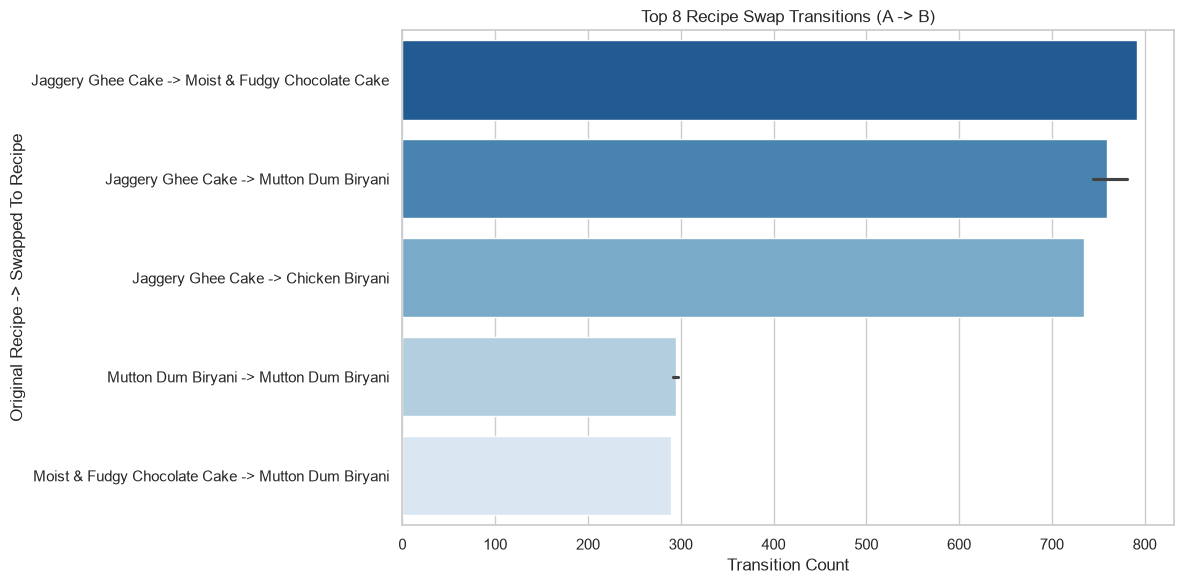

In [19]:
# Query top swap pairs from the view
query_swap_pairs = "SELECT * FROM v_common_swap_pairs LIMIT 10;"
df_swap_pairs = pd.read_sql(query_swap_pairs, engine)

# Display the top frequent swap transitions
display(df_swap_pairs)

# Plot top transition pairs as a horizontal bar chart
plt.figure(figsize=(12, 6))
df_swap_pairs['transition_label'] = df_swap_pairs['original_recipe_name'] + ' -> ' + df_swap_pairs['swapped_to_recipe_name']
sns.barplot(
    data=df_swap_pairs.head(8),
    x='transition_count',
    y='transition_label',
    palette='Blues_r',
    hue='transition_label',
    legend=False
)

# This chart highlights the most frequent recipe swap paths (A to B transitions) to understand common user dietary preference overrides.
plt.title('Top 8 Recipe Swap Transitions (A -> B)')
plt.xlabel('Transition Count')
plt.ylabel('Original Recipe -> Swapped To Recipe')
plt.tight_layout()
plt.show()

## 3. Plan-to-Order Conversion Rate by Template Goal
Evaluating the `v_template_goal_conversion` view to see how household health goals affect final grocery order conversion.

,template_goal,total_plans_created,total_orders_placed,conversion_rate_pct
0,weight-loss,1287,959,74.51
1,high-protein,1300,886,68.15
2,everyday,1313,699,53.24


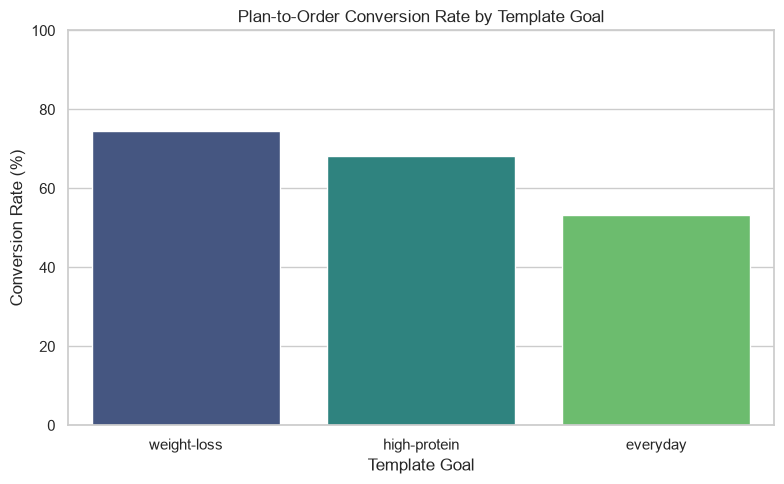

In [20]:
# Query plan-to-order conversion metrics grouped by template goal
query_conversion = "SELECT * FROM v_template_goal_conversion;"
df_conversion = pd.read_sql(query_conversion, engine)

# Display conversion rate table
display(df_conversion)

# Plot conversion rates across template goals
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_conversion,
    x='template_goal',
    y='conversion_rate_pct',
    palette='viridis',
    hue='template_goal',
    legend=False
)

# This chart compares plan-to-order conversion percentages across different household template goals (e.g., everyday, high-protein, weight-loss).
plt.title('Plan-to-Order Conversion Rate by Template Goal')
plt.xlabel('Template Goal')
plt.ylabel('Conversion Rate (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 4. Household Repeat-Dish Intervals
Analyzing the `v_household_repeat_intervals` view to examine household fatigue patterns and repetition frequency.

,avg_repeat_interval_days,min_repeat_interval_days,total_repeats_tracked
count,300.000000,300.000000,300.000000
mean,13.820667,1.276667,173.553333
std,14.067188,1.782521,110.059305
min,2.000000,0.000000,30.000000
25%,2.000000,0.000000,46.000000
50%,2.000000,0.000000,267.000000
75%,29.200000,3.000000,267.000000
max,41.000000,7.000000,267.000000


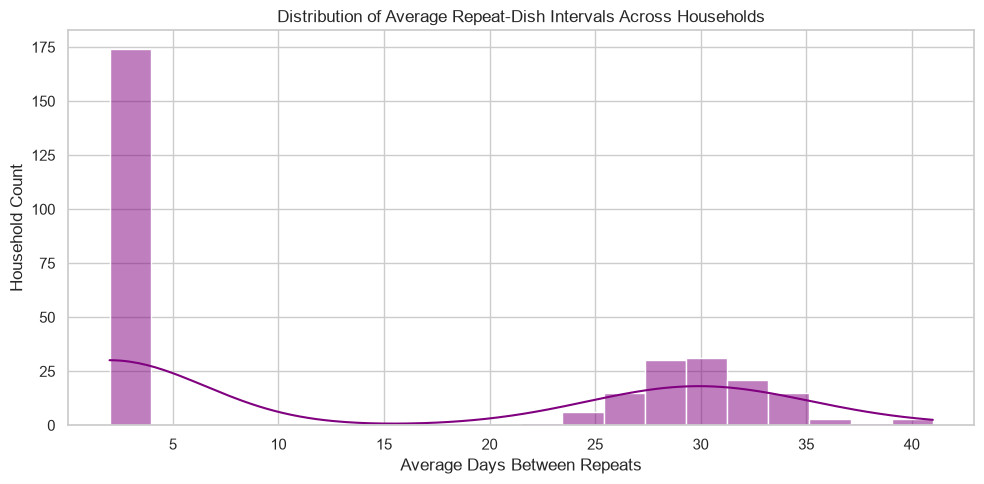

In [21]:
# Query repeat intervals per household
query_repeats = "SELECT * FROM v_household_repeat_intervals;"
df_repeats = pd.read_sql(query_repeats, engine)

# Display summary statistics of repeat intervals
display(df_repeats.describe())

# Plot distribution of average repeat intervals across households
plt.figure(figsize=(10, 5))
sns.histplot(df_repeats['avg_repeat_interval_days'], bins=20, kde=True, color='purple')

# This histogram shows the distribution of average days between repeated dishes for households, guiding the window size N for the recommendation fatigue constraint.
plt.title('Distribution of Average Repeat-Dish Intervals Across Households')
plt.xlabel('Average Days Between Repeats')
plt.ylabel('Household Count')
plt.tight_layout()
plt.show()